# Castle Labs · Sesión 4 · Práctica: tu ficha de alfa
**Castle Quant** · Vas a mover dos o tres parámetros, vas a correr el notebook y vas a salir con la ficha de tu propio modelo.

## ¿Qué es lo que vamos a hacer?
Vamos a repetir, en versión corta, el camino del Notebook 1: **C · Captura** y **A · Alfa**. No tienes que programar. Solamente cambias los parámetros de la sección 1 y la lista `features_elegidas` de la sección 5.

¿Y qué sale al final? Tu **ficha de alfa**. Una ficha de alfa no deja de ser más que la hoja de vida de un modelo: qué mercado mira, qué variables usa, qué pesos aprendió y qué tan buena fue su ventaja en la validación.

Haz de cuenta que es la ficha técnica de un carro. Te dice el motor y el consumo. No te dice cómo le va a ir en la carretera de mañana.

Tres reglas del método, para que las tengas en cuenta:
1. El orden del tiempo no se toca: 60 % para entrenar, 20 % para validar y 20 % para la prueba.
2. El tramo de prueba queda **sellado**. En este notebook no se mira.
3. La ficha cuenta lo que pasó en la validación. No promete nada hacia adelante.

¿Listo? Entonces vamos.

In [1]:
# El mapa del método: acá vamos a trabajar las dos primeras letras
# C · Captura + A · Alfa -> y_hat = model(x)

### Primero, el entorno

In [2]:
# Solamente en Google Colab: traemos las librerías del método (research.py, binance.py, models.py) y las velas de 12 horas
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('research.py'):
    !git clone --depth 1 https://github.com/JuliRey2000/metodo_CASTLE_castlequant.com.git
    %cd metodo_CASTLE_castlequant.com

In [3]:
# Si abriste el notebook desde la carpeta castle_labs/, vamos a subir a la raíz del repositorio (ahí están research.py y los datos)
if not os.path.exists('research.py') and os.path.exists(os.path.join('..', 'research.py')):
    os.chdir('..')
# Le decimos a Python dónde queda la raíz, para poder importar research, binance y models
sys.path.insert(0, os.getcwd())

In [4]:
# Las librerías de datos y de números
import polars as pl                         # DataFrames para series financieras
import numpy as np                          # Cálculo numérico
from datetime import datetime               # Manejo de fechas

# Las librerías de machine learning
import torch.nn as nn                       # Funciones de pérdida de PyTorch
import research                             # Utilidades del método: variables, entrenamiento y métricas
from models import LinearModel              # El modelo lineal del Notebook 1

# De dónde salen los datos
import binance                              # Descarga de velas y comisiones de Binance Futures

In [5]:
# Fijamos la semilla (random, numpy, torch) para que a todos nos dé el mismo resultado
research.set_seed(42)

In [6]:
# Para que las tablas de Polars se vean completas
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(100)
pl.Config.set_tbl_cols(-1);  # Mostrar todas las columnas sin truncar

---
## 1. Tus parámetros
Esta es la celdita que vas a cambiar. Tal como viene, el notebook reproduce el modelo de 12 horas del Notebook 1.

| Parámetro | Qué es | Qué puedes probar |
|---|---|---|
| `sym` | El mercado | `'BTCUSDT'`, `'ETHUSDT'` |
| `time_interval` | El tamaño de la vela | `'4h'`, `'6h'`, `'12h'` |
| `max_lags` | Cuántos retornos pasados se le ofrecen al modelo | `3`, `4`, `5` |
| `FUENTE` | De dónde salen las velas | `'csv'` (sin internet) o `'binance'` (descarga) |

Mira que el archivo `csv` del repositorio solamente trae **BTCUSDT en 12h**. Para otro mercado u otro intervalo toca usar `FUENTE = 'binance'`.

In [7]:
# El mercado que vamos a mirar
sym = 'BTCUSDT'
# El tamaño de la vela
time_interval = '12h'
# Cuántos rezagos (retornos pasados) le vamos a ofrecer al modelo
max_lags = 4
# De dónde salen las velas: 'csv' lee el archivo del repositorio, 'binance' descarga las velas de 1 minuto
FUENTE = 'csv'

In [8]:
# Qué tan lejos predecimos: 1 paso = 1 vela hacia adelante
forecast_horizon = 1
# El numerito que anualiza el Sharpe (cripto opera 365 días, 24 horas al día)
annualized_rate = research.sharpe_annualization_factor(time_interval, 365, 24)
annualized_rate

27.018512172212592

---
## 2. C · Captura
¿Qué es capturar? No deja de ser más que traer las velas a una tabla. Con `'csv'` las leemos del repositorio. Con `'binance'` las descargamos.

In [9]:
# El mismo rango de fechas del Notebook 1
start_date = datetime(2022, 1, 1)
end_date = datetime(2026, 10, 31)

In [10]:
if FUENTE == 'csv':
    # Las velas que ya trae el repositorio (las generó el Notebook 1)
    archivo = f'{sym}_{time_interval}_ohlc.csv'
    if not os.path.exists(archivo):
        raise FileNotFoundError(f"No existe {archivo}. El repositorio solo trae BTCUSDT en 12h: usa FUENTE = 'binance'")
    ts = pl.read_csv(archivo, try_parse_dates=True).sort('datetime')
elif FUENTE == 'binance':
    # Las mismas dos llamadas del Notebook 1. La primera vez baja unos 100 MB (uno o dos minuticos)
    # Para que lo tengas en cuenta: esta rama no se ejecutó contra Binance donde se armó este notebook (no había acceso a internet)
    binance.download_date_range(sym, start_date, end_date)
    ts = research.load_ohlc_timeseries_range(sym, time_interval, start_date, end_date)
else:
    raise ValueError("FUENTE debe ser 'csv' o 'binance'")
ts

datetime,open,high,low,close
datetime[μs],f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,47566.66,46210.55,46755.01
2022-01-01 12:00:00,46755.01,47943.77,46755.01,47704.35
2022-01-02 00:00:00,47704.35,47745.61,46749.99,47231.3
2022-01-02 12:00:00,47231.29,48000.0,46605.68,47280.0
2022-01-03 00:00:00,47280.01,47436.26,46717.26,47364.11
…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6


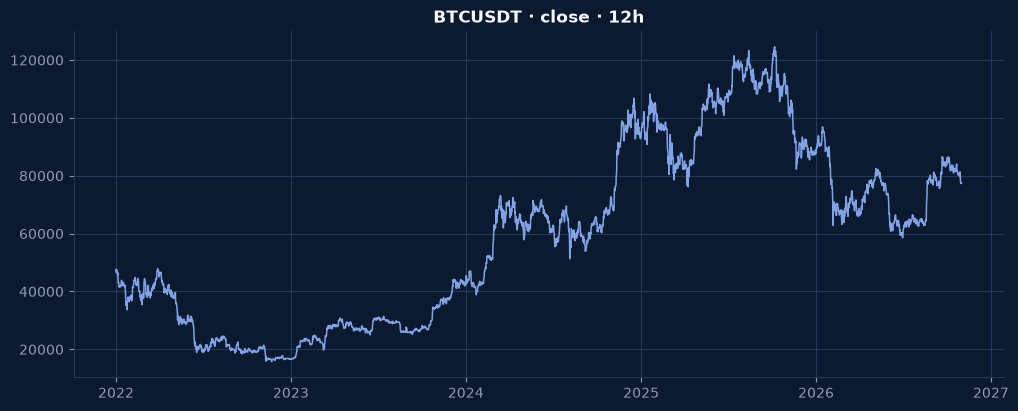

In [11]:
# Vamos a ver el precio de cierre
research.plot_static_timeseries(ts, sym, 'close', time_interval)

---
## 3. A · Alfa: el objetivo y sus rezagos
¿Qué es lo que queremos predecir? El retorno logarítmico de la vela. ¿Y con qué? Con los retornos de las velas que ya cerraron: `lag_1` es la vela anterior, `lag_2` la de antes, y así.

Haz de cuenta que vas manejando y solamente puedes mirar por el retrovisor. Los rezagos son eso: lo que ya pasó.

In [12]:
# El retorno logarítmico del cierre y sus rezagos. Quitamos las primeras filas, que quedan vacías
target = 'close_log_return'
ts = research.add_log_return_features(ts, 'close', forecast_horizon, max_no_lags=max_lags).drop_nulls()
ts

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-03 12:00:00,47364.11,47575.22,45665.4,46445.81,-0.019579,0.001777,0.001031,-0.009966,0.020101
2022-01-04 00:00:00,46445.8,46750.0,45931.61,46709.98,0.005672,-0.019579,0.001777,0.001031,-0.009966
2022-01-04 12:00:00,46709.97,47524.36,45445.57,45833.42,-0.018944,0.005672,-0.019579,0.001777,0.001031
2022-01-05 00:00:00,45833.41,47075.29,45710.23,46271.93,0.009522,-0.018944,0.005672,-0.019579,0.001777
2022-01-05 12:00:00,46271.93,46820.83,42270.0,43421.69,-0.063576,0.009522,-0.018944,0.005672,-0.019579
…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132


## 4. Partición en el tiempo
Vamos a partir los datos en tres tramos, en orden: 60 % de entrenamiento (ahí se estiman los pesos), 20 % de validación (ahí se elige el modelo) y 20 % de prueba, que queda sellada.

Es como estudiar para un parcial. Con los talleres aprendes, con el simulacro te mides, y el parcial se presenta una sola vez. ¿Listo?

In [13]:
# Qué parte va para validación y qué parte para prueba
val_size = 0.2
test_size = 0.2

In [14]:
# Partimos en orden de fechas. El tercer tramo (la prueba) no se guarda en ninguna variable: sigue sellado
ts_train, ts_val, _ = research.timeseries_split(ts, val_size, test_size)
len(ts_train), len(ts_val)

(2115, 705)

In [15]:
# Las fechas de los dos tramos que sí vamos a usar
print('Entrenamiento:', ts_train['datetime'][0], '->', ts_train['datetime'][-1])
print('Validación:   ', ts_val['datetime'][0], '->', ts_val['datetime'][-1])

Entrenamiento: 2022-01-03 12:00:00 -> 2024-11-25 12:00:00
Validación:    2024-11-26 00:00:00 -> 2025-11-13 00:00:00


## 5. Comparar modelos y elegir uno
Vamos a probar todas las combinaciones de hasta 3 rezagos. Cada una se entrena con el entrenamiento y se mide en la validación.

La pérdida es `L1Loss`, que no deja de ser más que el error absoluto. Castiga menos los valores extremos.

In [16]:
# Las candidatas: un rezago por cada número hasta max_lags
feature_pool = research.lag_col_names(target, max_lags)
feature_pool

['close_log_return_lag_1',
 'close_log_return_lag_2',
 'close_log_return_lag_3',
 'close_log_return_lag_4']

In [17]:
# Vamos a comparar todas las combinaciones de hasta 3 variables, ordenadas por Sharpe en la validación (tarda unos segunditos)
benchmark = research.benchmark_linear_models(ts, target, feature_pool, annualized_rate, max_no_features=3, loss=nn.L1Loss())
benchmark.select('features', 'win_rate', 'ev', 'sharpe', 'max_drawdown', 'weights', 'biases')

features,win_rate,ev,sharpe,max_drawdown,weights,biases
str,f64,f64,f64,f64,str,str
"""close_log_return_lag_1,close_log_return_lag_3,close_log_return_lag_4""",0.524823,0.001172,1.89588,-0.270243,"""[-0.00707 0.01568 -0.00088]""","""0.00028"""
"""close_log_return_lag_1,close_log_return_lag_3""",0.524823,0.001152,1.864097,-0.270243,"""[-0.00699 0.01524]""","""0.000278"""
"""close_log_return_lag_3""",0.519149,0.000847,1.369481,-0.324837,"""[0.01499]""","""0.000276"""
"""close_log_return_lag_1""",0.514894,0.000715,1.155473,-0.24286,"""[-0.00541]""","""0.000148"""
"""close_log_return_lag_1,close_log_return_lag_4""",0.514894,0.000598,0.966677,-0.216483,"""[-0.00514 -0.00273]""","""0.000166"""
…,…,…,…,…,…,…
"""close_log_return_lag_2""",0.506383,0.000483,0.780503,-0.302428,"""[-0.04919]""","""0.000236"""
"""close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_4""",0.512057,0.000468,0.75532,-0.276115,"""[-0.00525 -0.05008 0.0015 ]""","""0.000258"""
"""close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3""",0.506383,0.000362,0.584919,-0.36285,"""[-0.00679 -0.05226 0.008 ]""","""0.000253"""


In [18]:
# ¿Cuántos modelos comparamos? Guarda este número: entre más modelos pruebas, más fácil es que uno se vea bien por pura suerte
no_modelos = len(benchmark)
no_modelos

14

### Tu elección
Ahora sí te toca a ti. Escribe en `features_elegidas` las variables de tu modelo. Entre dos modelos que rinden casi igual, quédate con el más sencillo.

In [19]:
# Las variables de tu modelo (tal como viene, las del Notebook 1: rezagos 1 y 3)
features_elegidas = [f'{target}_lag_1', f'{target}_lag_3']

In [20]:
# Los datos de entrenamiento y de validación con tus variables
X_train, X_val, y_train, y_val = research.timeseries_train_val_split(ts, features_elegidas, target, val_size, test_size)
# El modelo arranca en cero: sin pesos y sin sesgo
model = LinearModel(len(features_elegidas))
model.apply(research.init_weights)
# Lo entrenamos con el entrenamiento y le pedimos la predicción en la validación
y_hat = research.batch_train_reg(model, X_train, X_val, y_train, y_val, criterion=nn.L1Loss())

In [21]:
# ¿Qué aprendió el modelo? Un peso por variable y el sesgo
pesos, sesgo = research.get_linear_params(model)
pesos, sesgo

(array([-0.00698682,  0.01524182], dtype=float32), 0.00027753887115977705)

## 6. ¿Cómo le fue en la validación?
La predicción se vuelve dirección. Si es positiva, compra. Si es negativa, venta.

Mira que estas métricas son **antes de comisiones**.

In [22]:
# Las métricas de trading de tu modelo
perf = research.eval_model_performance(y_val, y_hat, features_elegidas, target, annualized_rate)
perf

{'features': 'close_log_return_lag_1,close_log_return_lag_3',
 'target': 'close_log_return',
 'no_trades': 705,
 'win_rate': 0.524822695035461,
 'avg_win': 0.011908569655866272,
 'avg_loss': -0.010728415365229555,
 'best_trade': 0.09076853096485138,
 'worst_trade': -0.07499667257070541,
 'ev': 0.0011519881210193192,
 'std': 0.016697093082683485,
 'total_log_return': 0.8121516253186201,
 'compound_return': 2.2527498494838887,
 'max_drawdown': -0.27024269534740597,
 'equity_trough': -0.02639124169945717,
 'equity_peak': 1.0282458641768244,
 'sharpe': 1.8640972363198034}

In [23]:
# La caída máxima en porcentaje: viene en escala logarítmica y la pasamos con exp(x) - 1
caida_maxima_pct = np.exp(perf['max_drawdown']) - 1
caida_maxima_pct

np.float64(-0.23680575183462627)

## 7. La ventaja frente al costo
¿De qué sirve una ventaja que no alcanza para el peaje? De nada. Entonces vamos a ponerla al lado del costo.

Como primera aproximación suponemos el caso más exigente: entrar y salir a mercado en cada vela, o sea, dos comisiones *taker*. Si el valor esperado por operación (`ev`) no supera ese costo, no hay nada que operar. ¿Listo?

In [24]:
# Las comisiones de futuros en Binance: maker 0,02 % y taker 0,05 % por lado
maker_fee = binance.MAKER_FEE
taker_fee = binance.TAKER_FEE
# Lo que cuesta entrar y salir a mercado, en escala logarítmica (número positivo)
costo_ida_vuelta = -np.log(1 - 2 * taker_fee)
costo_ida_vuelta

np.float64(0.0010005003335835344)

In [25]:
# El valor esperado por operación frente al costo: por encima de 1, la ventaja cubre el costo
ev_sobre_costo = perf['ev'] / costo_ida_vuelta
perf['ev'], costo_ida_vuelta, ev_sobre_costo

(0.0011519881210193192,
 np.float64(0.0010005003335835344),
 np.float64(1.1514120309117686))

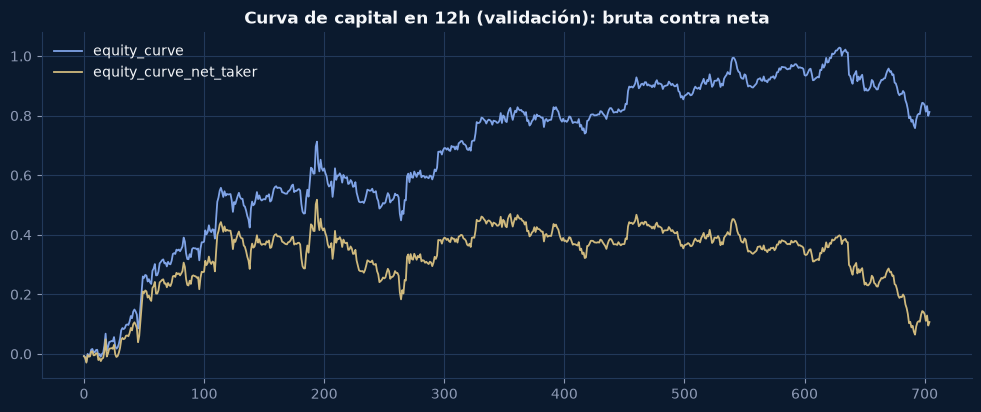

In [26]:
# Las operaciones de la validación y sus curvas ya descontando comisiones
model_trades = research.model_trade_results(y_val, y_hat)
model_trades = research.add_tx_fees_log(model_trades, maker_fee, taker_fee)
# La curva de capital bruta contra la neta (taker), en escala logarítmica
research.plot_multiple_lines(model_trades, ['equity_curve', 'equity_curve_net_taker'], f'Curva de capital en {time_interval} (validación): bruta contra neta')

## 8. Dos métricas más
El Sharpe castiga igual las sorpresas buenas y las malas. Estas dos miran el resultado desde otro lado. No es algo del otro mundo.

In [27]:
# El retorno de cada operación en la validación
retornos = model_trades['trade_log_return'].to_numpy()

In [28]:
# Sortino: no deja de ser más que un Sharpe en el que solamente cuentan como riesgo las operaciones perdedoras
desviacion_a_la_baja = np.sqrt(np.mean(np.minimum(retornos, 0) ** 2))
sortino = retornos.mean() / desviacion_a_la_baja * annualized_rate
sortino

np.float64(2.8886734652749206)

In [29]:
# Profit factor: lo que suman las ganadoras dividido entre lo que suman las perdedoras (por encima de 1, se gana más de lo que se pierde)
profit_factor = retornos[retornos > 0].sum() / -retornos[retornos < 0].sum()
profit_factor

np.float64(1.22597309363725)

---
## 9. Tu ficha de alfa
Ahora sí, vamos a juntar todo en una sola hoja.

In [30]:
# Para escribir los números con coma decimal
def num(x, decimales=2):
    return f'{x:.{decimales}f}'.replace('.', ',')

In [31]:
# Los nombres cortos de las variables y sus pesos
variables = [f.replace(f'{target}_', '') for f in features_elegidas]
pesos_txt = ' · '.join(f'{v} = {num(w, 4)}' for v, w in zip(variables, pesos))
# ¿La ventaja cubre el costo o no?
veredicto = 'la ventaja cubre el costo' if ev_sobre_costo > 1 else 'la ventaja NO cubre el costo'

print('=' * 66)
print('FICHA DE ALFA · Castle Labs · Sesión 4')
print('=' * 66)
print(f'Mercado:               {sym} (futuro perpetuo, Binance)')
print(f'Intervalo:             {time_interval}')
print(f'Variables:             {", ".join(variables)}')
print(f'Pesos:                 {pesos_txt}')
print(f'Sesgo:                 {num(sesgo, 6)}')
print('-' * 66)
print(f'Tramo de validación:   {ts_val["datetime"][0]:%Y-%m-%d} a {ts_val["datetime"][-1]:%Y-%m-%d} ({perf["no_trades"]} operaciones)')
print(f'Tasa de acierto:       {num(perf["win_rate"] * 100, 1)} %')
print(f'EV por operación:      {num(perf["ev"], 5)} (log)')
print(f'Sharpe anualizado:     {num(perf["sharpe"])} (antes de comisiones)')
print(f'Sortino anualizado:    {num(sortino)}')
print(f'Profit factor:         {num(profit_factor)}')
print(f'Caída máxima:          {num(caida_maxima_pct * 100, 1)} %')
print('-' * 66)
print(f'Costo de ida y vuelta: {num(costo_ida_vuelta, 5)} (2 comisiones taker)')
print(f'EV frente al costo:    {num(ev_sobre_costo)} veces -> {veredicto}')
print(f'Modelos comparados:    {no_modelos}')
print('-' * 66)
print('Mi hipótesis:')
print()
print('=' * 66)
print('Medido en la validación. El tramo de prueba sigue sellado.')

FICHA DE ALFA · Castle Labs · Sesión 4
Mercado:               BTCUSDT (futuro perpetuo, Binance)
Intervalo:             12h
Variables:             lag_1, lag_3
Pesos:                 lag_1 = -0,0070 · lag_3 = 0,0152
Sesgo:                 0,000278
------------------------------------------------------------------
Tramo de validación:   2024-11-26 a 2025-11-13 (705 operaciones)
Tasa de acierto:       52,5 %
EV por operación:      0,00115 (log)
Sharpe anualizado:     1,86 (antes de comisiones)
Sortino anualizado:    2,89
Profit factor:         1,23
Caída máxima:          -23,7 %
------------------------------------------------------------------
Costo de ida y vuelta: 0,00100 (2 comisiones taker)
EV frente al costo:    1,15 veces -> la ventaja cubre el costo
Modelos comparados:    14
------------------------------------------------------------------
Mi hipótesis:

Medido en la validación. El tramo de prueba sigue sellado.


Con los parámetros que trae el notebook, la ficha tiene que coincidir con el modelo de 12 horas del Notebook 1: Sharpe cercano a 1,86, EV cercano a 0,00115 y pesos cercanos a −0,0070 y 0,0152.

Y acuérdate de lo que muestra el Notebook 2: este mismo modelo, fuera de muestra, pierde y no le gana al azar. Al fin y al cabo, una ficha buena en la validación es el punto de partida, no la prueba de una ventaja.

---
## Preguntas
1. Tu EV por operación, ¿quedó por encima o por debajo del costo de ida y vuelta? Y si quedó muy cerquita, ¿qué le pasa a la ventaja si el deslizamiento te cuesta un poquito más?
2. Comparaste varios modelos y elegiste uno mirando la validación. ¿Por qué eso vuelve optimista el Sharpe de la ficha? ¿Qué número de la ficha te lo recuerda?
3. Mira el signo de cada peso. Uno negativo apuesta a que el movimiento se devuelve. Uno positivo, a que sigue. ¿Qué historia cuenta tu modelo? ¿Tiene sentido para ese mercado y ese intervalo?
4. Si cambiaste el intervalo a 4h o 6h, ¿qué le pasó al EV frente al costo? ¿Por qué operar más seguido no sale gratis?
5. El Sharpe y el Sortino de tu ficha, ¿se parecen o se alejan? ¿Qué te dice eso del tamaño de tus pérdidas frente al de tus ganancias?

## Tu entregable
1. Corre el notebook una vez tal como viene y confirma que la ficha coincide con el Notebook 1.
2. Cambia **máximo tres cosas** (mercado, intervalo, rezagos o variables elegidas) y saca tu propia ficha.
3. **Antes** de mirar el resultado, escribe en una línea tu hipótesis: por qué esas variables deberían predecir el retorno.
4. Copia la ficha completa, con tu hipótesis, y tráela a la sesión 5.
5. No abras el tramo de prueba. Eso se hace una sola vez, en el Notebook 2, cuando ya decidiste el modelo.

Al fin y al cabo, la idea no es que la ficha salga bonita, sino que sepas leerla. Esa es la idea.

> **Aviso.** Material educativo. No es asesoría financiera ni una recomendación de inversión. Los resultados son simulaciones sobre datos históricos y no garantizan resultados futuros.